<a href="https://colab.research.google.com/github/srikartankala/MLT9/blob/main/T9ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/cardekho.csv")
df.head()



,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


Exploratory Data Analysis


In [ ]:
df.info()
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB
(8128, 12)


In [ ]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats'],
      dtype='object')

Data Preprocessing


In [ ]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),221
engine,221


In [ ]:
df['max_power'].unique()[:20]

array(['74', '103.52', '78', '90', '88.2', '81.86', '57.5', '37', '67.1',
       '68.1', '108.45', '60', '73.9', nan, '67', '82', '88.5', '46.3',
       '88.73', '64.1'], dtype=object)

In [ ]:
df['mileage(km/ltr/kg)'] = df['mileage(km/ltr/kg)'].fillna(df['mileage(km/ltr/kg)'].median())

df['engine'] = df['engine'].fillna(df['engine'].median())

df['seats'] = df['seats'].fillna(df['seats'].median())

In [ ]:
df['max_power'] = pd.to_numeric(df['max_power'], errors='coerce')
df['max_power'] = df['max_power'].fillna(df['max_power'].median())
df['max_power'].dtype

dtype('float64')

In [ ]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),0
engine,0


In [ ]:
df['max_power'].unique()[:20]


array([ 74.  , 103.52,  78.  ,  90.  ,  88.2 ,  81.86,  57.5 ,  37.  ,
        67.1 ,  68.1 , 108.45,  60.  ,  73.9 ,  82.  ,  67.  ,  88.5 ,
        46.3 ,  88.73,  64.1 ,  98.6 ])

In [ ]:
df['name'].nunique()

2058

In [ ]:
df['owner'].value_counts()

,count
owner,
First Owner,5289
Second Owner,2105
Third Owner,555
Fourth & Above Owner,174
Test Drive Car,5


In [ ]:
# Extract brand
df['brand'] = df['name'].str.split().str[0]

# Remove original name
df.drop('name', axis=1, inplace=True)

In [ ]:
df = pd.get_dummies(
    df,
    columns=['brand', 'fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True
)

In [ ]:
df.head()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats,brand_Ashok,brand_Audi,brand_BMW,...,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2014,450000,145500,23.40,1248.0,74.00,5.0,False,False,False,...,True,False,False,True,False,True,False,False,False,False
1,2014,370000,120000,21.14,1498.0,103.52,5.0,False,False,False,...,True,False,False,True,False,True,False,True,False,False
2,2006,158000,140000,17.70,1497.0,78.00,5.0,False,False,False,...,False,False,True,True,False,True,False,False,False,True
3,2010,225000,127000,23.00,1396.0,90.00,5.0,False,False,False,...,True,False,False,True,False,True,False,False,False,False
4,2007,130000,120000,16.10,1298.0,88.20,5.0,False,False,False,...,False,False,True,True,False,True,False,False,False,False


In [ ]:
df = df.astype({col: 'int' for col in df.select_dtypes(include='bool').columns})
df.head()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats,brand_Ashok,brand_Audi,brand_BMW,...,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2014,450000,145500,23.40,1248.0,74.00,5.0,0,0,0,...,1,0,0,1,0,1,0,0,0,0
1,2014,370000,120000,21.14,1498.0,103.52,5.0,0,0,0,...,1,0,0,1,0,1,0,1,0,0
2,2006,158000,140000,17.70,1497.0,78.00,5.0,0,0,0,...,0,0,1,1,0,1,0,0,0,1
3,2010,225000,127000,23.00,1396.0,90.00,5.0,0,0,0,...,1,0,0,1,0,1,0,0,0,0
4,2007,130000,120000,16.10,1298.0,88.20,5.0,0,0,0,...,0,0,1,1,0,1,0,0,0,0


In [ ]:
corr = df.corr()
corr['selling_price'].sort_values(ascending=False)

,selling_price
selling_price,1.000000
max_power,0.747935
brand_BMW,0.527132
engine,0.458345
year,0.414092
brand_Lexus,0.362707
brand_Volvo,0.297832
brand_Jaguar,0.265154
fuel_Diesel,0.206521
brand_Mercedes-Benz,0.185855


Prepare X and Y

In [ ]:
# Features (Independent Variables)
X = df.drop('selling_price', axis=1)

# Target Variable (Dependent Variable)
y = df['selling_price']

print(X.head())

   year  km_driven  mileage(km/ltr/kg)  engine max_power  seats  brand_Ashok  \
0  2014     145500               23.40  1248.0        74    5.0        False   
1  2014     120000               21.14  1498.0    103.52    5.0        False   
2  2006     140000               17.70  1497.0        78    5.0        False   
3  2010     127000               23.00  1396.0        90    5.0        False   
4  2007     120000               16.10  1298.0      88.2    5.0        False   

   brand_Audi  brand_BMW  brand_Chevrolet  ...  fuel_Diesel  fuel_LPG  \
0       False      False            False  ...         True     False   
1       False      False            False  ...         True     False   
2       False      False            False  ...        False     False   
3       False      False            False  ...         True     False   
4       False      False            False  ...        False     False   

   fuel_Petrol  seller_type_Individual  seller_type_Trustmark Dealer  \
0       

In [ ]:
print(y.head())

0    450000
1    370000
2    158000
3    225000
4    130000
Name: selling_price, dtype: int64


In [ ]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (8128, 47)
Shape of y: (8128,)


Split into Training and Testing Data

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Features:", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Target :", y_train.shape)
print("Testing Target  :", y_test.shape)

Training Features: (6502, 47)
Testing Features : (1626, 47)
Training Target : (6502,)
Testing Target  : (1626,)


Feature Scaling

In [ ]:
numeric_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df[numeric_cols].isnull().sum()
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

X_test[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)



ValueError: could not convert string to float: ' '

Verify Scaled Data

In [ ]:
X_train.head()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats,brand_Ashok,brand_Audi,brand_BMW,brand_Chevrolet,...,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
6518,1.279377,-1.156592,1.157043,-0.513716,-0.212283,-0.426905,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
6144,-0.196059,0.170496,-0.001321,-0.515723,-0.127802,-0.426905,0,0,0,0,...,0,0,1,1,0,1,0,1,0,0
6381,-0.687871,1.370086,0.905225,-0.118286,-0.037388,-0.426905,0,0,0,0,...,1,0,0,1,0,1,1,0,0,0
438,-0.196059,0.855976,1.005952,-0.415360,-0.489460,-0.426905,0,0,0,0,...,1,0,0,1,0,1,0,1,0,0
5939,0.787565,-0.772038,1.144452,-0.917174,-0.685828,-0.426905,0,0,0,0,...,0,0,1,1,0,1,0,0,0,0


Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print("Intercept:", model.intercept_)

Intercept: 1004902.1932501986


In [ ]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
1971,198000,43476.486352
4664,500000,655011.828869
5448,425000,588550.349918
3333,150000,104482.521145
2316,525000,404700.798047
6870,160000,127232.521727
5953,450000,608494.098308
2418,570000,576612.263380
1811,170000,53443.444743
3608,135000,-43482.099058


In [ ]:
y_train.head()

,selling_price
6518,520000
6144,300000
6381,380000
438,530000
5939,335000


In [ ]:
from sklearn.metrics import r2_score

print(r2_score(y_test, y_pred))

0.8486765390570172


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))

MAE : 157639.36594990498
RMSE: 314944.7159682299
R2  : 0.8486765390570172


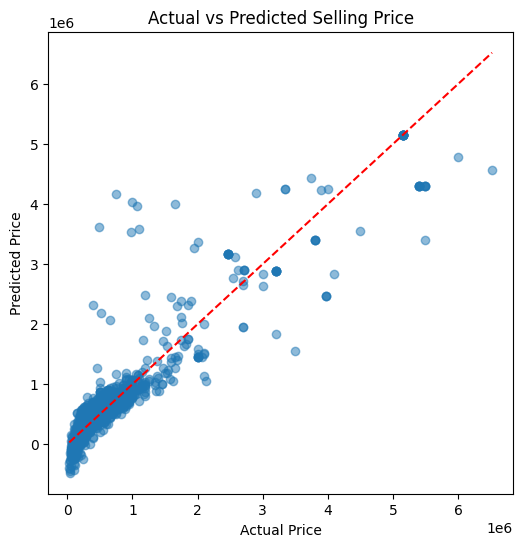

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Selling Price")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [ ]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(by='Coefficient', key=abs, ascending=False)
pd.set_option('display.float_format', '{:,.2f}'.format)

coefficients.head(15)

,Feature,Coefficient
22,brand_Lexus,"2,989,807.74"
8,brand_BMW,"2,255,426.54"
45,owner_Test Drive Car,"2,131,681.26"
21,brand_Land,"1,781,061.60"
36,brand_Volvo,"1,422,021.48"
18,brand_Jaguar,"1,019,092.83"
26,brand_Mercedes-Benz,"887,154.39"
33,brand_Tata,"-522,965.07"
11,brand_Datsun,"-521,711.65"
7,brand_Audi,"496,170.62"


In [ ]:
numeric_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

for col in numeric_cols:
    print("\n", col)
    print(df[col].dtype)
    print("Spaces:", (df[col] == ' ').sum())



 year
int64
Spaces: 0

 km_driven
int64
Spaces: 0

 mileage(km/ltr/kg)
float64
Spaces: 0

 engine
float64
Spaces: 0

 max_power
float64
Spaces: 0

 seats
float64
Spaces: 0
X shape: (8128, 47)
y shape: (8128,)


In [ ]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

df[numeric_cols].isnull().sum()

,0
year,0
km_driven,0
mileage(km/ltr/kg),0
engine,0
max_power,0
seats,0


In [ ]:

X = df.drop('selling_price', axis=1)
y = df['selling_price']

print("X shape:", X.shape)
print("y shape:", y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X shape: (8128, 47)
y shape: (8128,)
X_train: (6502, 47)
X_test : (1626, 47)
y_train: (6502,)
y_test : (1626,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

X_test[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

X_train[numeric_cols].head()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats
6518,1.279377,-1.156592,1.157043,-0.513716,-0.212283,-0.426905
6144,-0.196059,0.170496,-0.001321,-0.515723,-0.127802,-0.426905
6381,-0.687871,1.370086,0.905225,-0.118286,-0.037388,-0.426905
438,-0.196059,0.855976,1.005952,-0.415360,-0.489460,-0.426905
5939,0.787565,-0.772038,1.144452,-0.917174,-0.685828,-0.426905


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully.")
print(y_pred[:10])

Predictions generated successfully.
[ 43476.48635232 655011.8288692  588550.34991804 104482.52114541
 404700.79804748 127232.52172699 608494.09830828 576612.2633805
  53443.44474331 -43482.09905845]


Perfomance Metrics

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
print("Model Performance Metrics")

mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)


Model Performance Metrics
Mean Absolute Error: 157639.36594990498
Mean Squared Error: 99190174116.30908
Root Mean Squared Error: 314944.71596823004
R² Score: 0.8486765390570171


Logistic Regression

1. Median price for classification target

In [ ]:
median_price = df['selling_price'].median()

print("Median Selling Price:", median_price)

Median Selling Price: 450000.0


In [ ]:
df['price_category'] = (df['selling_price'] >= 450000).astype(int)
df[['selling_price', 'price_category']].head(10)
df['price_category'].value_counts()

,count
price_category,
1,4137
0,3991


In [ ]:
X = df.drop(['selling_price', 'price_category'], axis=1)
y = df['price_category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8128, 47)
y shape: (8128,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (6502, 47)
X_test : (1626, 47)
y_train: (6502,)
y_test : (1626,)


In [ ]:
numeric_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]
from sklearn.preprocessing import StandardScaler

scaler_log = StandardScaler()

X_train[numeric_cols] = scaler_log.fit_transform(
    X_train[numeric_cols]
)

X_test[numeric_cols] = scaler_log.transform(
    X_test[numeric_cols]
)

In [ ]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression()
log_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [ ]:
y_pred = log_model.predict(X_test)

print("Predictions generated successfully.")
print(y_pred[:20])

Predictions generated successfully.
[1 1 0 0 0 0 1 1 1 1 0 0 0 1 1 1 0 0 0 0]


In [ ]:
y_prob = log_model.predict_proba(X_test)

print(y_prob[:10])

[[1.37180685e-03 9.98628193e-01]
 [3.73590822e-01 6.26409178e-01]
 [6.69842367e-01 3.30157633e-01]
 [9.42942893e-01 5.70571071e-02]
 [9.99641337e-01 3.58663147e-04]
 [9.99998181e-01 1.81899985e-06]
 [2.72290612e-02 9.72770939e-01]
 [5.92099604e-02 9.40790040e-01]
 [5.15431769e-06 9.99994846e-01]
 [6.22512718e-02 9.37748728e-01]]


Comparison of Actual vs. Predicted

In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(15)

,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,0,0
4,0,0
5,0,0
6,1,1
7,1,1
8,1,1
9,1,1


Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.906519065190652


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[735  63]
 [ 89 739]]


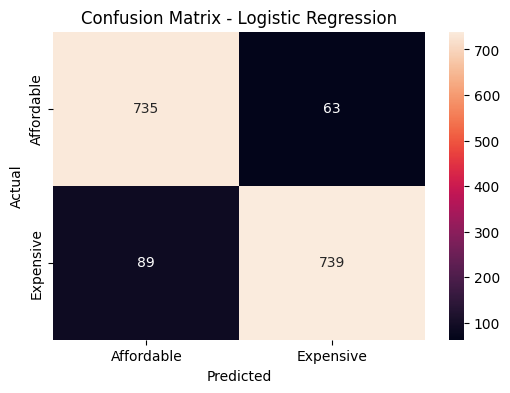

In [ ]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Affordable', 'Expensive'],
    yticklabels=['Affordable', 'Expensive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Principal Component Analysis

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("cardekho.csv")
numeric_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

X = df[numeric_cols].copy()

print("Dataset shape:", X.shape)
print("\nFirst 5 rows:")
X.head()

Dataset shape: (8128, 6)

First 5 rows:


,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats
0,2014,145500,23.40,1248.0,74,5.0
1,2014,120000,21.14,1498.0,103.52,5.0
2,2006,140000,17.70,1497.0,78,5.0
3,2010,127000,23.00,1396.0,90,5.0
4,2007,120000,16.10,1298.0,88.2,5.0


In [ ]:
X['max_power'] = pd.to_numeric(
    X['max_power'].replace(r'^\s*$', np.nan, regex=True),
    errors='coerce'
)

X['max_power'] = X['max_power'].fillna(
    X['max_power'].median()
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("\nFirst 5 rows:")
print(X_scaled[:5])

Scaled data shape: (8128, 6)

First 5 rows:
[[ 0.04846419  1.33836255  0.98620891 -0.41800262 -0.48806691 -0.43429672]
 [ 0.04846419  0.88741086  0.42637197  0.07814289  0.34643932 -0.43429672]
 [-1.9297752   1.24109846 -0.42576921  0.0761583  -0.37499019 -0.43429672]
 [-0.94065551  1.01120152  0.88712272 -0.12428448 -0.03576001 -0.43429672]
 [-1.68249528  0.88741086 -0.82211394 -0.31877352 -0.08664454 -0.43429672]]


In [ ]:
import numpy as np

print("NaN values:", np.isnan(X_scaled).sum())
print("Infinite values:", np.isinf(X_scaled).sum())
print("NaNs per feature:")
print(pd.DataFrame(X_scaled, columns=numeric_cols).isna().sum())

NaN values: 663
Infinite values: 0
NaNs per feature:
year                    0
km_driven               0
mileage(km/ltr/kg)    221
engine                221
max_power               0
seats                 221
dtype: int64


In [ ]:
for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Remaining NaNs:", np.isnan(X_scaled).sum())
print("Scaled data shape:", X_scaled.shape)

Remaining NaNs: 0
Scaled data shape: (8128, 6)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("PCA data shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nCumulative explained variance:")
print(np.cumsum(pca.explained_variance_ratio_))

PCA data shape: (8128, 6)

Explained variance ratio:
[0.42382998 0.25830534 0.12784437 0.11438982 0.05140953 0.02422096]

Cumulative explained variance:
[0.42382998 0.68213532 0.80997969 0.92436951 0.97577904 1.        ]


In [ ]:
pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca_3.shape)

print(
    "Variance retained:",
    pca_3.explained_variance_ratio_.sum() * 100,
    "%"
)

Original shape: (8128, 6)
Reduced shape: (8128, 3)
Variance retained: 80.9979689368032 %


Naive Bayes Classification

In [ ]:
df['price_category'] = (
    df['selling_price'] >= 450000
).astype(int)

print(df['price_category'].value_counts())
print("\nDataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())

price_category
1    4137
0    3991
Name: count, dtype: int64

Dataset shape: (8128, 13)
Missing values:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
price_category          0
dtype: int64


In [ ]:
df['brand'] = df['name'].str.split().str[0]

X = df.drop(
    ['name', 'selling_price', 'price_category'],
    axis=1
)
y = df['price_category']

numeric_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols = X.select_dtypes(
    include=['object']
).columns

for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

X = X.astype({
    col: 'int'
    for col in X.select_dtypes(include='bool').columns
})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Remaining missing values:", X.isnull().sum().sum())

X shape: (8128, 365)
y shape: (8128,)
Remaining missing values: 0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6502, 365)
X_test: (1626, 365)
y_train: (6502,)
y_test: (1626,)


In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred = nb_model.predict(X_test)

print("First 20 predictions:")
print(y_pred[:20])

First 20 predictions:
[1 0 0 0 0 0 1 1 1 0 0 0 0 1 1 1 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.8376383763837638
Accuracy percentage: 83.76383763837639 %


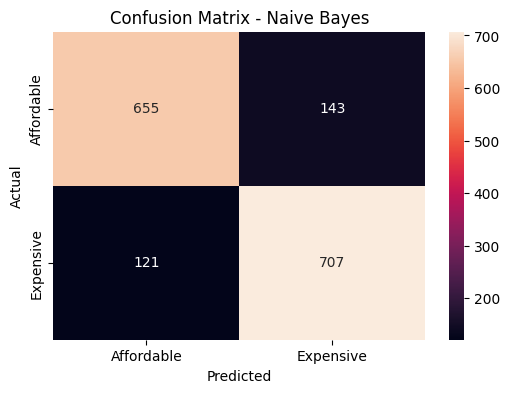

[[655 143]
 [121 707]]


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Affordable', 'Expensive'],
    yticklabels=['Affordable', 'Expensive']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

print(cm)

Support Vector Machine

In [ ]:
df['brand'] = df['name'].str.split().str[0]

df['max_power'] = pd.to_numeric(
    df['max_power'].replace(r'^\s*$', np.nan, regex=True),
    errors='coerce'
)

X = df.drop(
    ['name', 'selling_price', 'price_category'],
    axis=1
)
y = df['price_category']

numeric_cols = [
    'year',
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats'
]

for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

categorical_cols = X.select_dtypes(
    include=['object']
).columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Dataset shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print("Numeric columns present:",
      all(col in X.columns for col in numeric_cols))

Dataset shape: (8128, 47)
Missing values: 0
Numeric columns present: True


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_svm = StandardScaler()

X_train_svm = X_train.copy()
X_test_svm = X_test.copy()

X_train_svm[numeric_cols] = scaler_svm.fit_transform(
    X_train_svm[numeric_cols]
)

X_test_svm[numeric_cols] = scaler_svm.transform(
    X_test_svm[numeric_cols]
)

print("X_train:", X_train_svm.shape)
print("X_test:", X_test_svm.shape)
print("Missing values:", X_train_svm.isnull().sum().sum())

X_train: (6502, 47)
X_test: (1626, 47)
Missing values: 0


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear')

svm_model.fit(X_train_svm, y_train)

SVC(kernel='linear')

In [ ]:
y_pred_svm = svm_model.predict(X_test_svm)

print("First 20 predictions:")
print(y_pred_svm[:20])

First 20 predictions:
[1 1 0 0 0 0 1 1 1 1 0 0 0 1 1 1 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Accuracy:", accuracy_svm)
print("Accuracy percentage:", accuracy_svm * 100, "%")

Accuracy: 0.9034440344403444
Accuracy percentage: 90.34440344403444 %


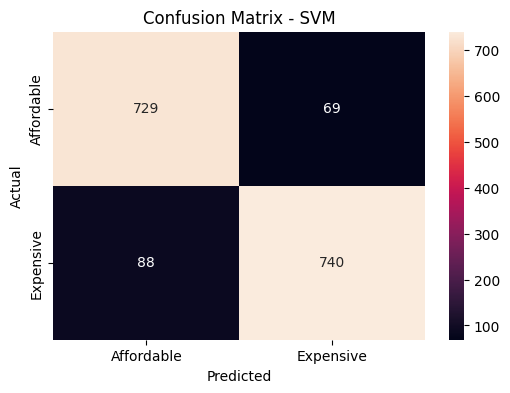

[[729  69]
 [ 88 740]]


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=['Affordable', 'Expensive'],
    yticklabels=['Affordable', 'Expensive']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVM')
plt.show()

print(cm_svm)

In [9]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

df['brand'] = df['name'].str.split().str[0]
df['max_power'] = pd.to_numeric(df['max_power'].replace(r'^\s*$', np.nan, regex=True), errors='coerce')

df['price_category'] = (df['selling_price'] >= 450000).astype(int)

X = df.drop(['name', 'selling_price', 'price_category'], axis=1)
y = df['price_category']

numeric_cols = ['year', 'km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']
for col in numeric_cols:
    X[col] = X[col].fillna(X[col].median())

categorical_cols = X.select_dtypes(include=['object']).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler_svm = StandardScaler()
X_train_svm = X_train.copy()
X_test_svm = X_test.copy()

X_train_svm[numeric_cols] = scaler_svm.fit_transform(X_train_svm[numeric_cols])
X_test_svm[numeric_cols] = scaler_svm.transform(X_test_svm[numeric_cols])


non_linear_svm = SVC(kernel='rbf', C=1.0, gamma='scale')
non_linear_svm.fit(X_train_svm, y_train)

y_pred_rbf = non_linear_svm.predict(X_test_svm)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print(f"Non-Linear SVM (RBF) Accuracy: {accuracy_rbf * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rbf, target_names=['Affordable', 'Expensive']))

Non-Linear SVM (RBF) Accuracy: 92.74%

Classification Report:
              precision    recall  f1-score   support

  Affordable       0.91      0.95      0.93       798
   Expensive       0.95      0.91      0.93       828

    accuracy                           0.93      1626
   macro avg       0.93      0.93      0.93      1626
weighted avg       0.93      0.93      0.93      1626

